# 1. System Environment Configuration
Set up the Python environment to include custom modules from the parent directory.

In [1]:
import sys
import os
from pathlib import Path

# Add parent directory to system path to import custom packages
sys.path.append(str(Path(os.getcwd()).parent))

# 2. Import Dependencies
Import necessary libraries for quantum simulation, noise modeling, and numerical analysis.

In [2]:
# Custom packages
from packages.unitary import *
from packages.povms import *
from packages.utils import *
from packages.states import *
from packages.linalg import *
from packages.decomposition import kak_decomposition

# Qiskit Core & Quantum Info
from qiskit import QuantumCircuit
from qiskit.quantum_info import (
    DensityMatrix, 
    Operator,
    Statevector
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Qiskit Aer & Noise Models
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    thermal_relaxation_error,
)

# Numerical & Optimization tools
import numpy as np
from scipy.optimize import brute, brentq

# 3. Load SIC-POVM Fiducial Vector
Load the fiducial vector defining the Symmetric Informationally Complete (SIC) POVM.
Reference: PhysRevA.86.062107

In [3]:
# Load SIC-POVM fiducial vector
sic_fiducial_vector = np.load(r'../data/sic_phi_vectors/PRA_86_062107.npy')

# 4. Experiment Parameters
Define parameters for the noisy simulation.

In [4]:
num_shots = 5_000_000        # Number of measurement shots
num_qubits = 6               # System size
use_cloud_backend = False
save_intermediate_data = True # For convergence plotting
optimization_mode = 2        # 2: Optimized SIC-POVM (S4 method)

# 5. Configure Noise Model (T1/T2 Thermal Relaxation)
Construct a realistic noise model based on thermal relaxation.
- T1 (Relazation time): Mean 50us
- T2 (Dephasing time): Mean 70us (constrained by 2*T1)
- Gate times: U1(0ns), U2(50ns), U3(100ns), CNOT(300ns)

In [5]:
# Total qubits involved: system qubits + ancilla qubits (for POVM dilation)
# Since each system qubit needs 1 ancilla, total = 2 * num_qubits
total_simulation_qubits = 2 * num_qubits

# Generate random T1/T2 times for each qubit based on normal distribution
# Mean T1=50us, T2=70us
rng = np.random.default_rng(seed=42) # Fixed seed for reproducibility
t1_values = rng.normal(50e3, 10e3, total_simulation_qubits)
t2_values = rng.normal(70e3, 10e3, total_simulation_qubits)

# Physical constraint: T2 <= 2 * T1
t2_values = np.array([min(t2_values[j], 2 * t1_values[j]) for j in range(total_simulation_qubits)])

# Gate duration parameters (in nanoseconds)
time_u1 = 0
time_u2 = 50 
time_u3 = 100
time_cx = 300
time_reset = 1000 
time_measure = 1000 

# Create error objects for each qubit
errors_u1  = [thermal_relaxation_error(t1, t2, time_u1) for t1, t2 in zip(t1_values, t2_values)]
errors_u2  = [thermal_relaxation_error(t1, t2, time_u2) for t1, t2 in zip(t1_values, t2_values)]
errors_u3  = [thermal_relaxation_error(t1, t2, time_u3) for t1, t2 in zip(t1_values, t2_values)]
errors_reset = [thermal_relaxation_error(t1, t2, time_reset) for t1, t2 in zip(t1_values, t2_values)]
errors_measure = [thermal_relaxation_error(t1, t2, time_measure) for t1, t2 in zip(t1_values, t2_values)]

# Create CNOT errors (2-qubit gate error is tensor product of 1-qubit errors)
# errors_cx[control][target]
errors_cx = [[thermal_relaxation_error(t1a, t2a, time_cx).expand(
             thermal_relaxation_error(t1b, t2b, time_cx))
              for t1a, t2a in zip(t1_values, t2_values)]
               for t1b, t2b in zip(t1_values, t2_values)]

# Assemble the NoiseModel
noise_model = NoiseModel()

# Add single-qubit errors
for j in range(total_simulation_qubits):
    noise_model.add_quantum_error(errors_u1[j], "u1", [j])
    noise_model.add_quantum_error(errors_u2[j], "u2", [j])
    noise_model.add_quantum_error(errors_u3[j], "u3", [j])
    # noise_model.add_quantum_error(errors_reset[j], "reset", [j]) # Optional
    # noise_model.add_quantum_error(errors_measure[j], "measure", [j]) # Optional

# Add CNOT errors
# Note: The original code logic for adding CX errors seemed specific to the dilation topology.
# Here we add errors between system qubit (j) and its ancilla (j + num_qubits)
# assuming standard dilation mapping.
for j in range(num_qubits):
    control_qubit = j
    target_qubit = j + num_qubits # Ancilla index
    
    # Error when system controls ancilla
    error_sys_anc = errors_cx[target_qubit][control_qubit] # Note: Qiskit error expansion order might be target-control
    noise_model.add_quantum_error(error_sys_anc, "cx", [control_qubit, target_qubit])
    
    # Error when ancilla controls system (if needed)
    error_anc_sys = errors_cx[control_qubit][target_qubit]
    noise_model.add_quantum_error(error_anc_sys, "cx", [target_qubit, control_qubit])

print("Noise Model Configured.")
print(noise_model)

Noise Model Configured.
NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx', 'u2', 'u3']
  Instructions with noise: ['u2', 'u3', 'cx']
  Qubits with noise: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
  Specific qubit errors: [('u2', (0,)), ('u2', (1,)), ('u2', (2,)), ('u2', (3,)), ('u2', (4,)), ('u2', (5,)), ('u2', (6,)), ('u2', (7,)), ('u2', (8,)), ('u2', (9,)), ('u2', (10,)), ('u2', (11,)), ('u3', (0,)), ('u3', (1,)), ('u3', (2,)), ('u3', (3,)), ('u3', (4,)), ('u3', (5,)), ('u3', (6,)), ('u3', (7,)), ('u3', (8,)), ('u3', (9,)), ('u3', (10,)), ('u3', (11,)), ('cx', (0, 6)), ('cx', (6, 0)), ('cx', (1, 7)), ('cx', (7, 1)), ('cx', (2, 8)), ('cx', (8, 2)), ('cx', (3, 9)), ('cx', (9, 3)), ('cx', (4, 10)), ('cx', (10, 4)), ('cx', (5, 11)), ('cx', (11, 5))]


# 6. State Preparation & Observable
Initialize the target GHZ state and define the observable (Projector |GHZ><GHZ|) for fidelity estimation.

In [6]:
random_state = get_random_state(num_qubits)
zero_state = get_zero_state(num_qubits)
one_state = get_one_state(num_qubits)
ghz_state = get_ghz_state(num_qubits)
target_state_vector = ghz_state

observable_matrix = DensityMatrix.from_instruction(target_state_vector).data

# 7. Circuit Construction Functions
Functions to build the SIC-POVM measurement circuit using Naimark's dilation.

In [7]:
def attach_ancilla_and_measure(qc, measured_qubits, two_qubit_subcircuit):
    """Expands circuit with ancilla for POVM."""
    num_system_qubits = qc.num_qubits
    num_measurements = len(measured_qubits)
    
    expanded_circuit = QuantumCircuit(num_system_qubits + num_measurements, num_measurements * 2)
    expanded_circuit.compose(qc, qubits=range(num_system_qubits), inplace=True)
    
    for i, target_qubit in enumerate(measured_qubits):
        ancilla_index = num_system_qubits + i 
        expanded_circuit.compose(two_qubit_subcircuit, qubits=[target_qubit, ancilla_index], inplace=True)
    
    expanded_circuit.barrier()
    
    for i, target_qubit in enumerate(measured_qubits):
        expanded_circuit.measure(target_qubit, i)
        ancilla_index = num_system_qubits + i 
        expanded_circuit.measure(ancilla_index, num_measurements + i)
        
    return expanded_circuit

def construct_sic_measurement_circuit(target_state_qc, sic_fiducial, optimization_mode=0, measured_qubits=None):
    """Constructs the compiled SIC-POVM circuit."""
    unitary_matrix = sic_phi_2_unitary(sic_fiducial)
    requires_cnot_relabeling = False
    
    if optimization_mode == 0: # Standard
        povm_unitary_circuit = unitary2circuit(unitary_matrix)
        
    elif optimization_mode == 1: # KAK Optimization
        def interaction_strength(gamma2):
            control_op = controlled_U3_pauli(0, gamma2, 0)
            _, _, z = kak_decomposition(unitary_matrix @ control_op)
            return np.abs(z) 
        
        search_range = (0, 1 * np.pi)
        gamma2_opt = brute(interaction_strength, [search_range], Ns=1000, full_output=False, finish=None)
        # Refinement step omitted for brevity, brute force is usually close enough
        
        control_op_opt = controlled_U3_pauli(0, gamma2_opt, 0)
        povm_unitary_circuit = unitary2circuit(unitary_matrix @ control_op_opt)
        
    elif optimization_mode == 2: # S4 Analytical Optimization
        u_s, phases, requires_cnot_relabeling = get_sic_parameters(unitary_matrix) 
        povm_unitary_circuit = QuantumCircuit(2)
        from qiskit.circuit.library import UnitaryGate
        povm_unitary_circuit.append(UnitaryGate(u_s), [0])
        povm_unitary_circuit.rx(np.arccos(1/np.sqrt(3)), 1)
        povm_unitary_circuit.rz(3 * np.pi / 4, 1)
        povm_unitary_circuit.cx(1, 0)
        povm_unitary_circuit.h(1)       
    
    if measured_qubits is None:
        measured_qubits = range(target_state_qc.num_qubits)
        
    final_circuit = attach_ancilla_and_measure(target_state_qc, measured_qubits, povm_unitary_circuit)
    return final_circuit, requires_cnot_relabeling

# 8. Compilation and Execution
Run the simulation with the configured T1/T2 noise model.

Starting simulation with 5000000 shots...
Simulation complete. Collected 5000000 outcomes.


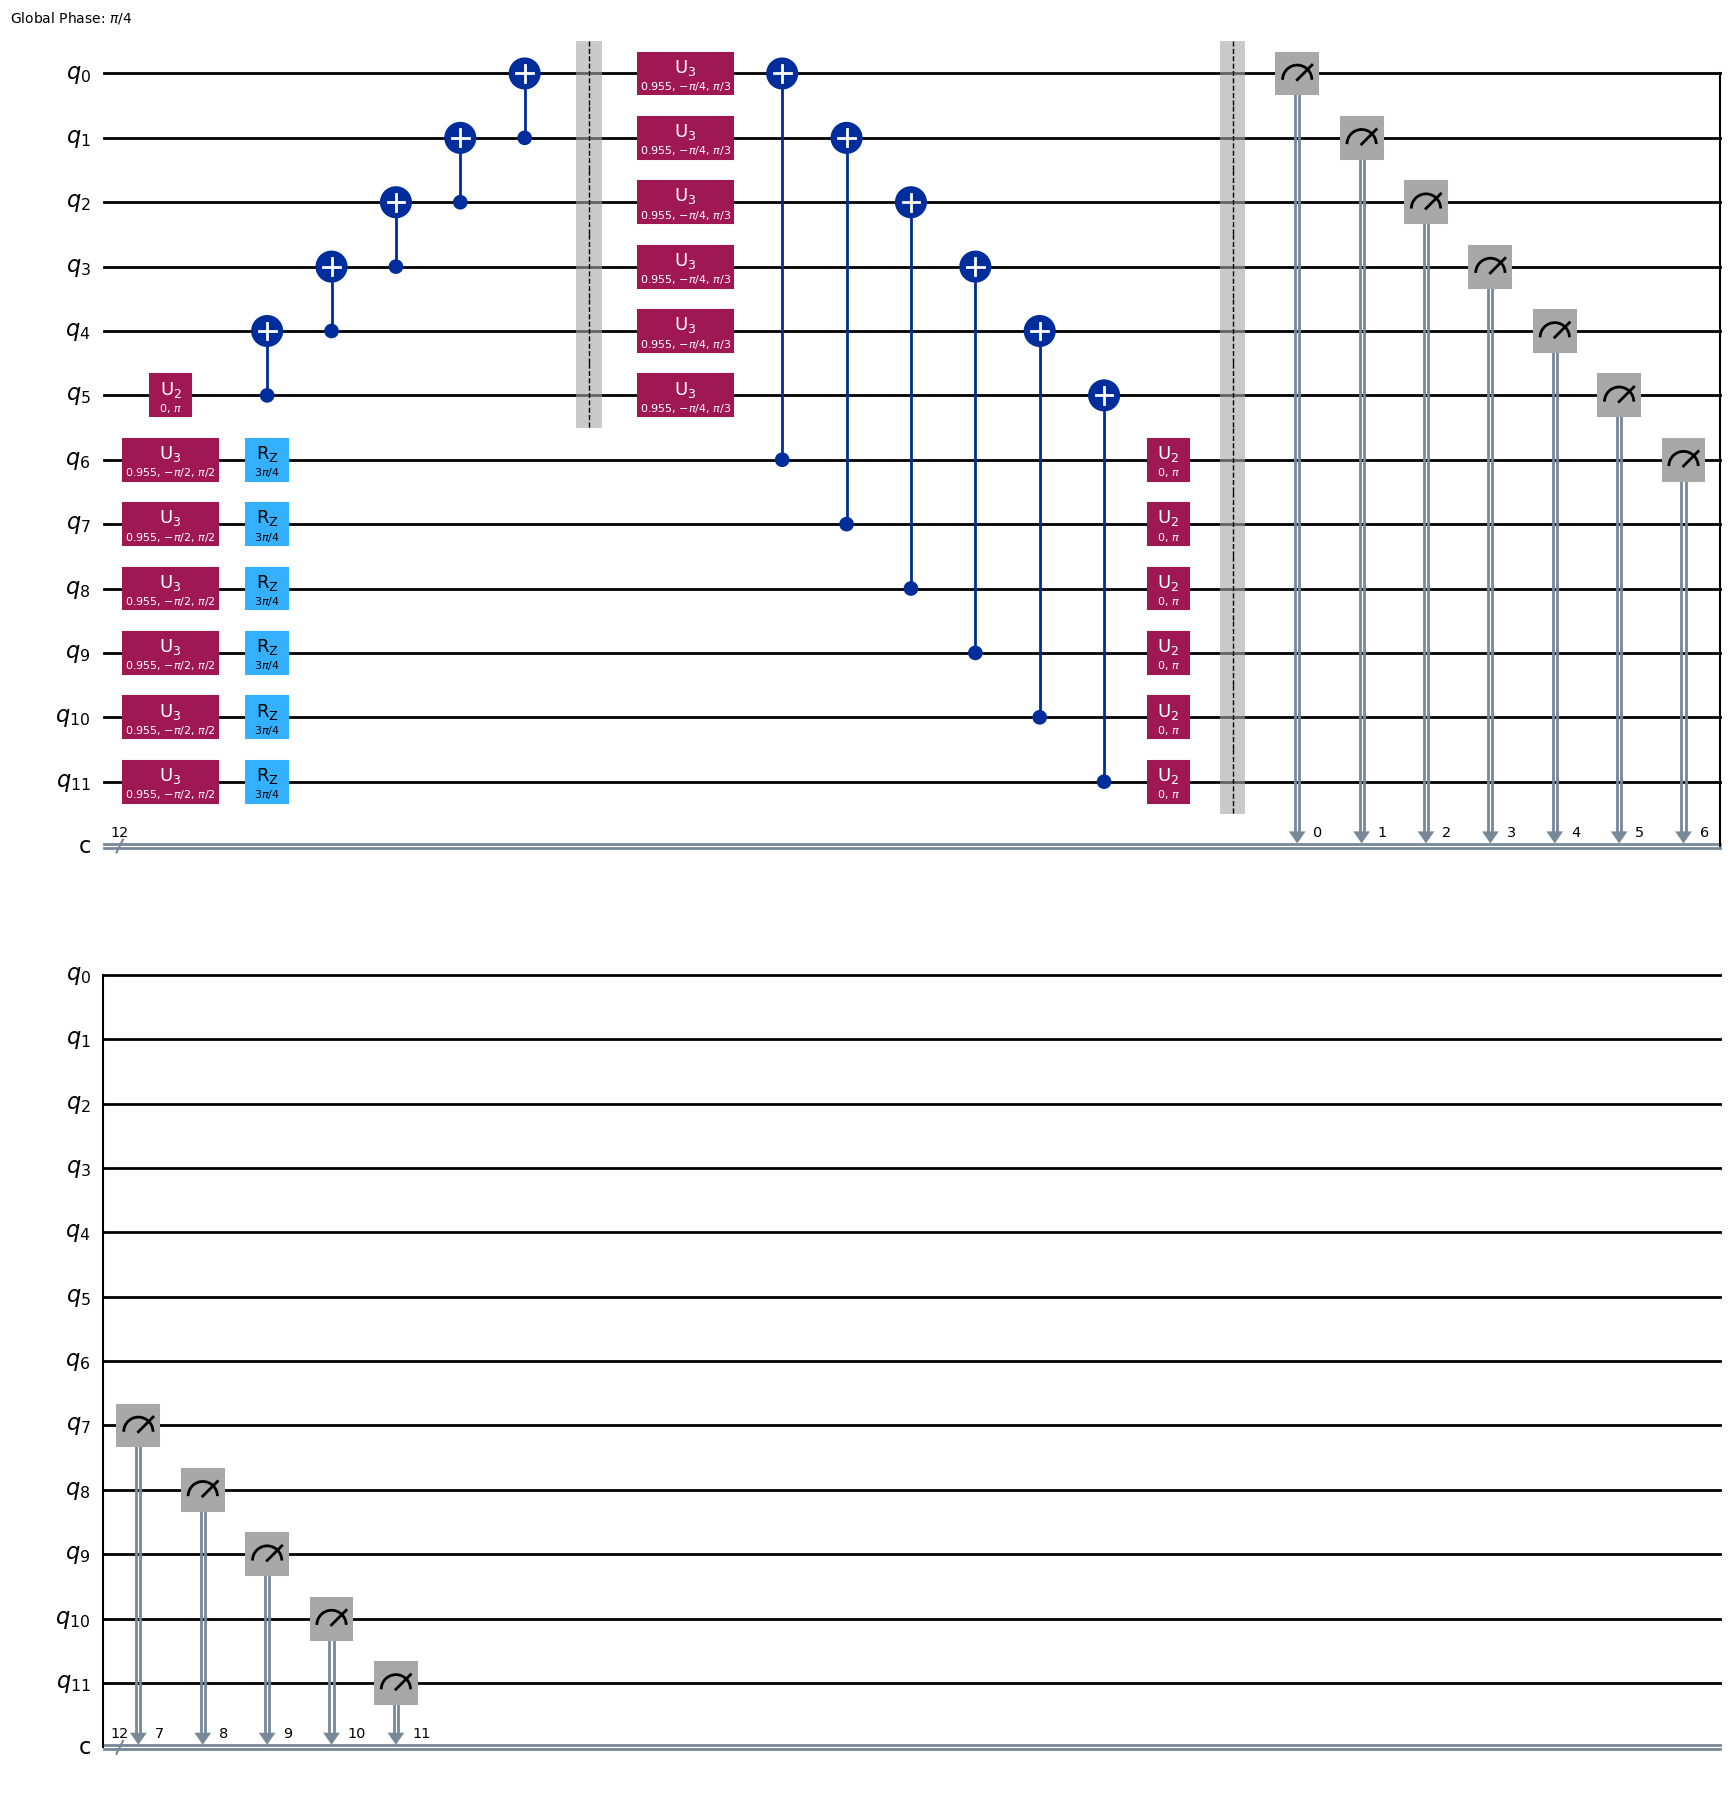

In [8]:
# 1. Build Circuit
target_state_circuit = target_state_vector
sic_measurement_circuit, requires_relabeling = construct_sic_measurement_circuit(
    target_state_circuit, 
    sic_fiducial_vector, 
    optimization_mode
)

# 2. Configure Backend with Noise
backend_simulator = AerSimulator(noise_model=noise_model)

# 3. Transpile (optimization_level=0 to preserve structure)
pass_manager = generate_preset_pass_manager(optimization_level=0, backend=backend_simulator)
transpiled_circuit = pass_manager.run(sic_measurement_circuit)

# 4. Execute
print(f"Starting simulation with {num_shots} shots...")
simulation_job = backend_simulator.run(transpiled_circuit, shots=num_shots, memory=True)
shot_results = simulation_job.result().get_memory()
print(f"Simulation complete. Collected {len(shot_results)} outcomes.")

# Optional: Visualize
transpiled_circuit.draw('mpl')

# 9. Classical Shadow Post-processing
Reconstruct shadows and estimate fidelity.

In [9]:
def estimate_shadow_expectation(measurement_bitstrings, sic_fiducial, apply_relabeling, return_trajectory, estimation_func, *func_args):
    Sp_inv, povm_map = compute_frame_operator_inv_and_dict(sic_fiducial, apply_relabeling)
    
    local_snapshot_cache = {
        b: devectorize_matrix(Sp_inv @ v) for b, v in povm_map.items()
    }
    
    computed_values_cache = {}
    
    def compute_val(bitstring):
        if bitstring not in computed_values_cache:
            outcomes = snapshot_data_split(bitstring)
            snapshots = [local_snapshot_cache[o] for o in outcomes]
            global_rho = compute_kronecker_product(snapshots)
            computed_values_cache[bitstring] = estimation_func(global_rho, *func_args)
        return computed_values_cache[bitstring]
    
    if not return_trajectory:
        return sum(compute_val(b) for b in measurement_bitstrings) / len(measurement_bitstrings)
    else:
        return [compute_val(b) for b in measurement_bitstrings]

# 10. Compute Fidelity

In [10]:
def expectation_value(rho, observable):
    return np.trace(observable @ rho)

fidelity_trajectory = estimate_shadow_expectation(
    shot_results, 
    sic_fiducial_vector, 
    requires_relabeling, 
    save_intermediate_data, 
    expectation_value, 
    observable_matrix
)

print(f"Final Fidelity (Noisy): {np.mean(fidelity_trajectory).real:.6f}")
print(f"Last Shot Estimate: {fidelity_trajectory[-1]}")

Final Fidelity (Noisy): 0.952248
Last Shot Estimate: (8.499999999999993-4.599000840645145e-17j)


# 12. Visualization: Convergence Analysis
Plot the convergence of the estimated fidelity as the number of shots increases.

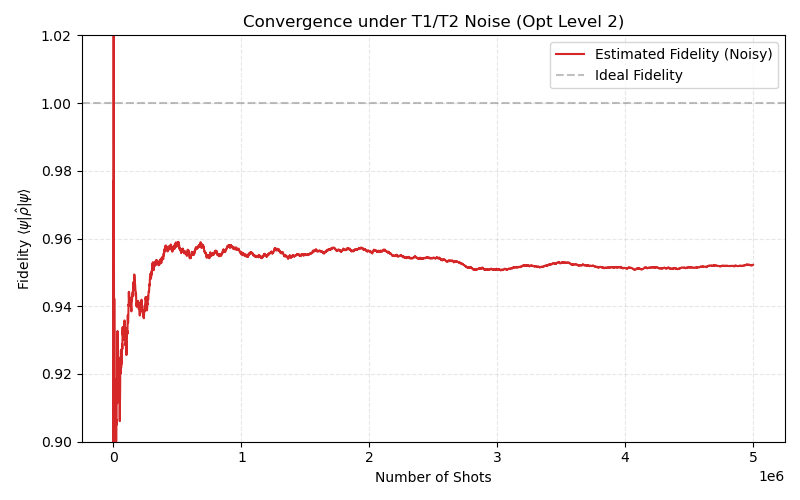

In [11]:
%matplotlib widget
from matplotlib import pyplot as plt

fidelity_values = np.array(fidelity_trajectory).real
cumulative_average = np.cumsum(fidelity_values) / np.arange(1, len(fidelity_values) + 1)

# Downsampling
step = 1000
indices = list(range(0, len(cumulative_average), step))
if len(cumulative_average)-1 not in indices: indices.append(len(cumulative_average)-1)

plt.figure(figsize=(8, 5))
plt.ylim(0.9,1.02)
plt.plot(indices, cumulative_average[indices], label='Estimated Fidelity (Noisy)', color='#d62728') # Red for noisy

# Ideal baseline (1.0)
plt.axhline(y=1.0, color='grey', linestyle='--', alpha=0.5, label='Ideal Fidelity')

plt.xlabel('Number of Shots')
plt.ylabel(r'Fidelity $\langle \psi | \hat{\rho} | \psi \rangle$')
plt.title(f'Convergence under T1/T2 Noise (Opt Level {optimization_mode})')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()